[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB11_bistable_whole_brain.ipynb)

# Day 2 · Chapter 5 · Notebook 11 — Bistable regions: neural activity, BOLD, and a network that changes in time

*Reference notebook: not run in class. It shows, step by step, the model presented in the slides.*

The model of the slides (Rabuffo et al. 2021): every region is a population of spiking neurons with a **down** and an
**up** state, wired by the same human connectome as NB10 and driven by noise. We compare two pre-run 10-minute
simulations, **without** ($G=0$) and **with** ($G=0.7$) coupling. Look at how fast up/down switches (EEG-like) become
slow BOLD fluctuations, and at FC patterns that **change in time**.

> **Question.** Can bistable regions, wired by the connectome, make the network change its FC pattern in time
> (dynamic FC)? **Virtual experiment.** The same brain and the same noise, with coupling off ($G=0$) and on ($G=0.7$).
> **What would change our mind.** A dynamic FC as flat with coupling as without it.

In [1]:
# @title Setup (run once)
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
# Load the connectome and the two pre-run simulations
from src import connectome, meanfield, wholebrain
sc, fc, labels = connectome.load_hcp(weights="counts", normalize="max", homotopic=0.5)   # NB10's fibre counts and mirror links, scaled to a maximum of 1
net = np.array([l.split("_")[2] for l in labels])                  # resting-state network of each region
NETS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
order = np.concatenate([np.where(net == n)[0] for n in NETS])     # regions sorted by network, for display
u = np.triu_indices(100, 1)
cache = np.load("../data/cache/nb11_bistable.npz")                 # pre-run simulations (dev/cache_nb11_bistable.py)
ETA0, GS = float(cache["eta0"]), cache["G"]                          # excitability -4.3; couplings 0 and 0.7
RATES, EEG, BOLD = cache["rates"], cache["eeg"], cache["bold"]       # per run: 2 min of rates, 10 min EEG-like, 10 min BOLD
dt_r, TR = float(cache["dt_rate"]), float(cache["TR"])               # 20 ms, 2 s

## 1. One region: bistable, or not

> **Gist.** Each region is the QIF population of NB05. Its excitability $\eta$ decides what it can do: in a middle range
> a quiet **down** state and an active **up** state coexist (bistability, NB08), and input from other regions can switch it.

<details><summary>Equations (for the curious)</summary>

$$
\tau\dot r_i = \frac{\Delta}{\pi\tau} + 2 r_i v_i,\qquad
\tau\dot v_i = v_i^2 + \eta + J\tau r_i - (\pi\tau r_i)^2 + G\sum_j W_{ij} r_j + \text{noise}
$$

$r_i$: firing rate of region $i$; $v_i$: its mean membrane potential; $J=14.5$, $\Delta=0.7$, $\tau=1$ ms (Montbrió,
Pazó & Roxin 2015; Rabuffo et al. 2021). $W_{ij}$: connectome weight (fibre counts scaled to a maximum of 1, plus
mirror connections between hemispheres, as in NB10). The two 10-minute runs use $\eta=-4.3$ in every region and take
several minutes to compute (`dev/cache_nb11_bistable.py`).
</details>

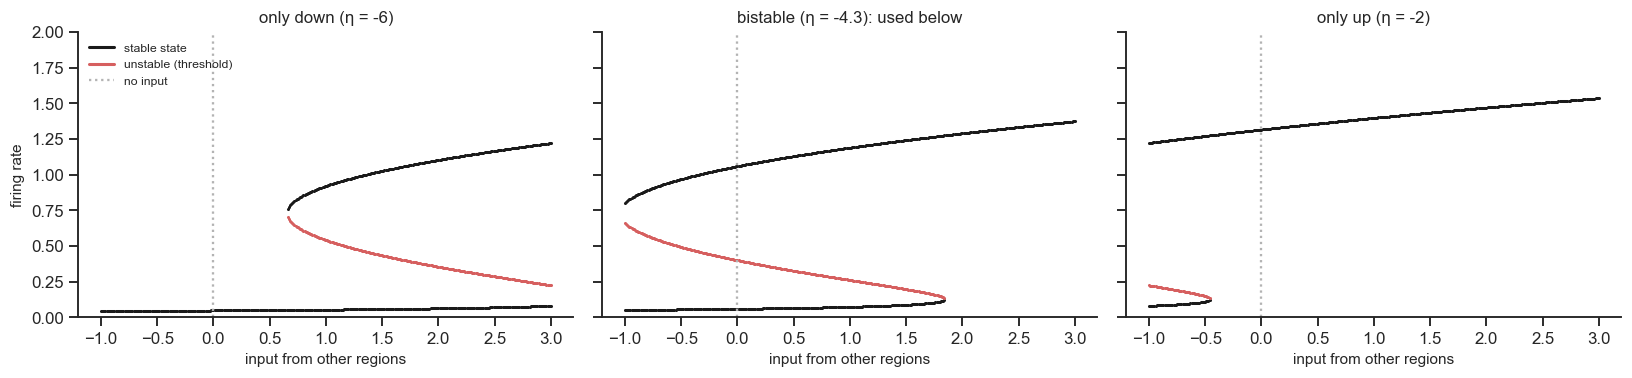

In [2]:
# @title Stable and unstable states of one region, for three excitabilities
I = np.linspace(-1.0, 3.0, 401)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for a_, (eta, name) in zip(ax, [(-6.0, "only down (η = -6)"), (ETA0, f"bistable (η = {ETA0}): used below"), (-2.0, "only up (η = -2)")]):
    br = meanfield.mpr_branches(I, eta, 14.5, 0.7)
    for stable, c, lab in [(True, "k", "stable state"), (False, "C3", "unstable (threshold)")]:
        b = np.array([(x[0], x[1]) for x in br if x[3] == stable])
        if len(b): a_.plot(b[:, 0], b[:, 1], ".", c=c, ms=2)
        a_.plot([], [], c=c, lw=2, label=lab)
    a_.axvline(0, c="0.7", ls=":", label="no input")
    a_.set(xlabel="input from other regions", title=name, ylim=(0, 2))
ax[0].set_ylabel("firing rate"); ax[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

**Middle:** with no input the region can sit down or up; enough input from active neighbours ends the down branch (a
saddle-node, NB08) and the region jumps up. **Left:** it stays down unless it receives a lot of input. **Right:** it is
always up.

## 2. The whole brain: without and with coupling

> **Gist.** 100 bistable regions with noise. Without coupling, noise alone is too weak to switch a region up. With
> coupling, a region that switches up pushes its neighbours, which may switch too: a **cascade** over the connectome.

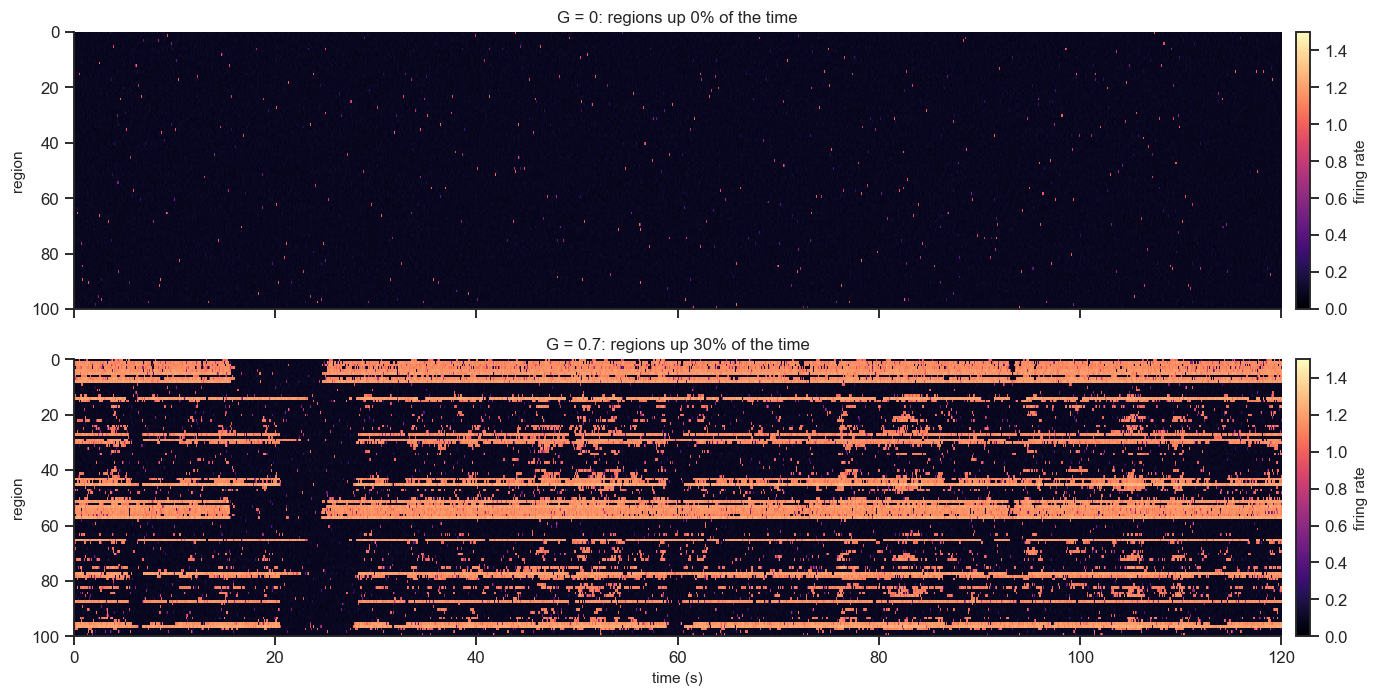

In [3]:
# @title Firing rate of every region over the first 2 minutes, without and with coupling
fig, ax = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
for a_, G, r in zip(ax, GS, RATES):
    im = a_.imshow(r.T, aspect="auto", cmap="magma", vmin=0, vmax=1.5, extent=[0, len(r) * dt_r, 100, 0], interpolation="nearest")
    a_.set(ylabel="region", title=f"G = {G:g}: regions up {100 * (r > 0.3).mean():.0f}% of the time")
    plt.colorbar(im, ax=a_, label="firing rate", pad=0.01)
ax[1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

**Without coupling** (top) every region stays down, with tiny flickers. **With coupling** (bottom) regions switch up
and down in groups. Some stay up most of the time (horizontal lines): they receive the most input from the connectome.
Around 20 s the whole brain goes down together and comes back: one cascade can switch the entire network.

## 3. What EEG and fMRI would see

> **Gist.** EEG sums the activity of many neurons: fast. BOLD follows activity slowly: a short burst gives a response
> that peaks after about 5 s and lasts about 20 s (Balloon–Windkessel model, Friston et al. 2000). Same 2 minutes,
> three views.

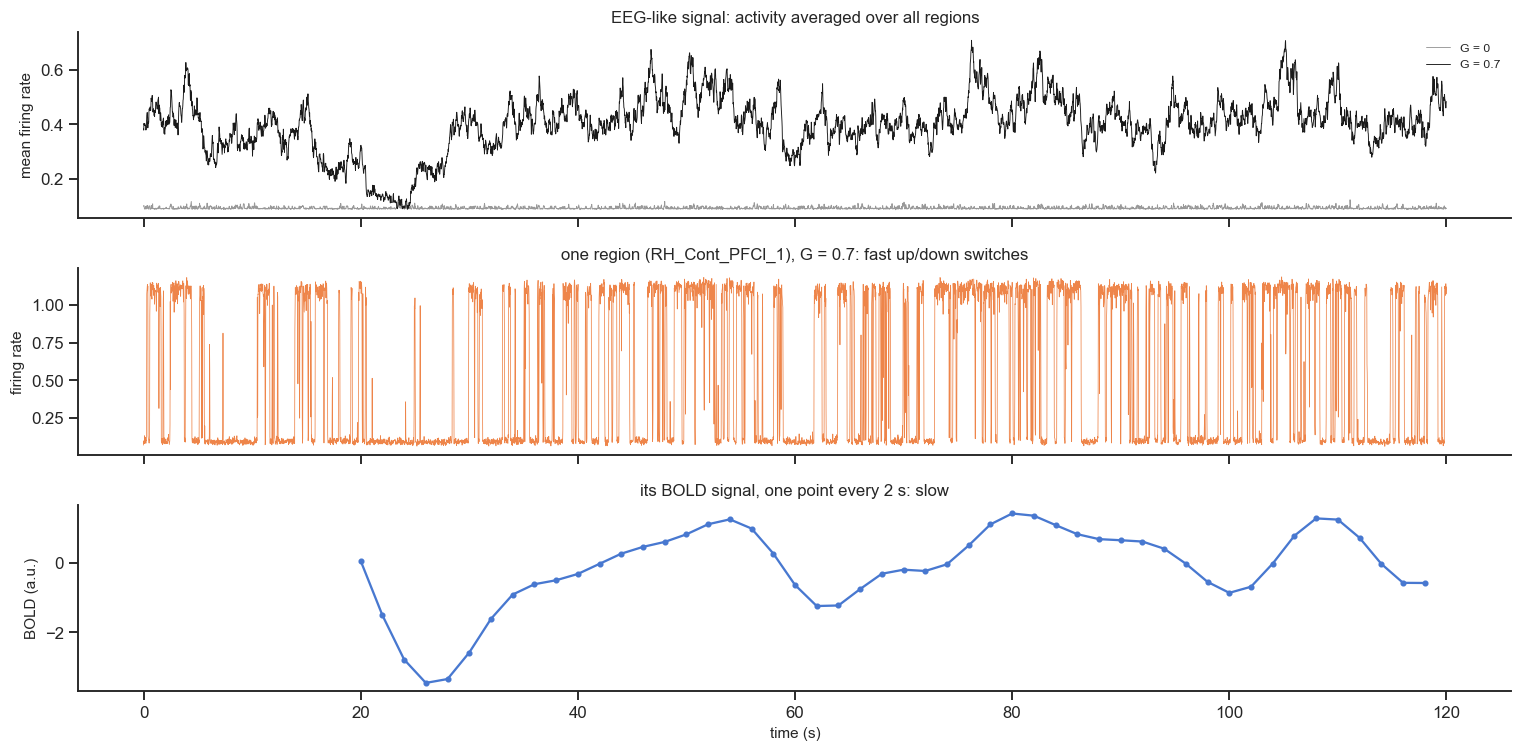

In [4]:
# @title EEG-like signal of the whole brain, and firing rate and BOLD of one region (same 2 minutes)
rates, y = RATES[1], BOLD[1]
tr = np.arange(len(rates)) * dt_r; tb = 20 + np.arange(len(y)) * TR             # BOLD starts 20 s into the run
k = int(np.argmax(((rates > 0.3)[1:] != (rates > 0.3)[:-1]).sum(0)))            # the region that switches most often
name = labels[k].replace("7Networks_", "")
fig, ax = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
for G, e, c in zip(GS, EEG, ["0.6", "k"]):
    ax[0].plot(tr, e[:len(tr)], c=c, lw=0.6, label=f"G = {G:g}")
ax[0].set(ylabel="mean firing rate", title="EEG-like signal: activity averaged over all regions"); ax[0].legend(fontsize=8, loc="upper right")
ax[1].plot(tr, rates[:, k], "C1", lw=0.5); ax[1].set(ylabel="firing rate", title=f"one region ({name}), G = {GS[1]:g}: fast up/down switches")
m = tb <= tr[-1]
ax[2].plot(tb[m], y[m, k], "C0", lw=1.5, marker="o", ms=3)
ax[2].set(xlabel="time (s)", ylabel="BOLD (a.u.)", title="its BOLD signal, one point every 2 s: slow")
plt.tight_layout(); plt.show()

The BOLD signal starts at 20 s: the first 20 s are discarded while the BOLD model settles. The fast switches are lost in BOLD; what survives is their slow density: long stays up raise the BOLD signal seconds
later, and the global down state at about 20 s gives the deep dip at about 25 s. As in the slides, fast local events
drive the slow network activity.

## 4. A network that changes in time

> **Gist.** Compute FC in one-minute **windows** and compare the FC of every pair of windows (dynamic FC, as in the
> slides). A static network gives the same FC in every window; recurring patterns show up as squares off the diagonal.

One number summarises it: the **variance** of the similarities between non-overlapping windows. Near zero for noise,
high for a network that moves between patterns. We compare it with the value of the measured data (computed as in NB13).

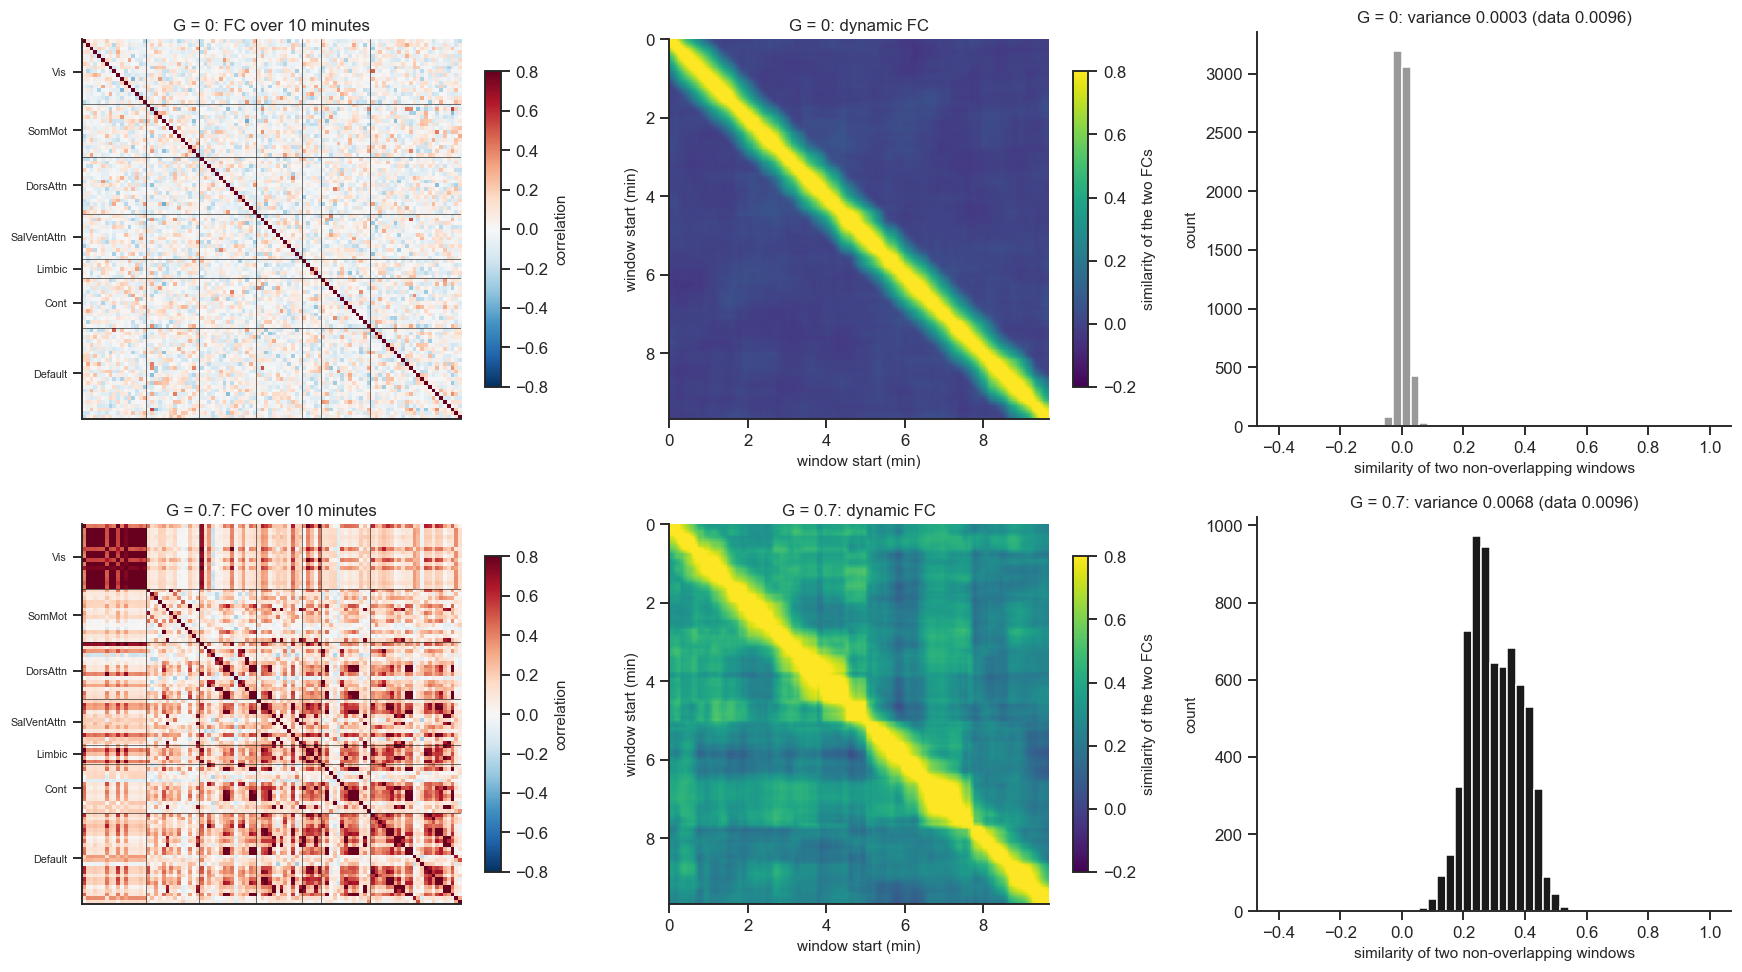

variance of dynamic FC: 26 times larger with coupling; model 0.0068, measured data 0.0096


In [5]:
# @title FC, dynamic FC, and the spread of window similarities, without and with coupling
def window_fc(x, w=30, step=2):                                    # FC in windows of w volumes (60 s), every step volumes
    return np.array([np.corrcoef(x[s:s + w].T)[u] for s in range(0, len(x) - w + 1, step)])

def dynamic_fc(x, w=30, step=2):
    F = window_fc(x, w, step); D = np.corrcoef(F)                 # similarity of the FC of every pair of windows
    far = np.abs(np.subtract.outer(np.arange(len(F)), np.arange(len(F)))) * step >= w      # windows that do not overlap
    return D, D[np.triu(far)]

ts = np.load("../data/empirical/fmri_ds000228_schaefer100.npz")["ts"]                   # measured BOLD of NB09, 10 people
var_data = np.concatenate([dynamic_fc(x)[1] for x in ts]).var()                           # as in NB13

fig, ax = plt.subplots(2, 3, figsize=(16, 9), gridspec_kw=dict(width_ratios=[1, 1, 1]))
var = []
for row, G, y in zip(ax, GS, BOLD):
    D, vals = dynamic_fc(y); var.append(vals.var())
    im0 = row[0].imshow(np.corrcoef(y.T)[np.ix_(order, order)], cmap="RdBu_r", vmin=-0.8, vmax=0.8)
    mids = np.cumsum([0] + [np.sum(net == n) for n in NETS])
    for e in mids[1:-1] - 0.5: row[0].axhline(e, c="k", lw=0.4); row[0].axvline(e, c="k", lw=0.4)
    row[0].set(xticks=[], title=f"G = {G:g}: FC over 10 minutes")
    row[0].set_yticks((mids[:-1] + mids[1:]) / 2 - 0.5, NETS, fontsize=7)
    plt.colorbar(im0, ax=row[0], shrink=0.8, label="correlation")
    im = row[1].imshow(D, cmap="viridis", vmin=-0.2, vmax=0.8, extent=[0, len(y) * TR / 60, len(y) * TR / 60, 0])
    row[1].set(xlabel="window start (min)", ylabel="window start (min)", title=f"G = {G:g}: dynamic FC")
    plt.colorbar(im, ax=row[1], shrink=0.8, label="similarity of the two FCs")
    row[2].hist(vals, bins=np.linspace(-0.4, 1, 50), color="0.6" if G == 0 else "k")
    row[2].set(xlabel="similarity of two non-overlapping windows", ylabel="count", title=f"G = {G:g}: variance {vals.var():.4f} (data {var_data:.4f})")
plt.tight_layout(); plt.show()
print(f"variance of dynamic FC: {var[1] / var[0]:.0f} times larger with coupling; model {var[1]:.4f}, measured data {var_data:.4f}")

**Without coupling** (top) FC is noise and two different minutes are unrelated: only the diagonal band of overlapping
windows is bright. **With coupling** (bottom) FC has structure and the dynamic FC shows **squares**: the network stays
in one pattern, moves to another, and sometimes returns. Nothing was fitted to dynamic FC: it emerges from bistable
regions, noise and the connectome. With coupling the spread reaches about two thirds of the measured one (titles of
the histograms): the model moves between patterns, a little less than the brain. (Rough comparison: the data are
5.6-minute recordings of children watching a film, band-passed; the model runs are 10 minutes.)

## 5. Take-home

* Bistable regions (down and up state) with noise, wired by the connectome, make a whole-brain model with fast activity.
* **Without coupling** nothing happens; **with coupling** local switches spread as cascades over the connectome.
* The same simulation gives a fast **EEG-like** signal and a slow **BOLD** signal, and an FC that **changes in time**
  (dynamic FC) without being fitted to it (Rabuffo et al. 2021).

### Homework
*To do at home, after the class. Each 10-minute simulation takes several minutes.*
1. **Window length.** Recompute the dynamic FC of section 4 with windows of 20 and 45 volumes. Does the variance
   change? Why does a too-short window make even noise look dynamic?
2. **Edges instead of windows.** Use the edge time series of NB09 on the model BOLD (`BOLD[1]`). Does the model
   show co-activation events?
3. **Coupling.** Run `wholebrain.mpr_network` (see `dev/cache_nb11_bistable.py`) for 10 s with $G = 0.5$ and $G = 1$.
   What happens to the up/down switching when the coupling is too weak or too strong?
4. **Hopf vs bistable.** Compute the variance of dynamic FC for the Hopf model of NB10 at $a=-0.02$ and $a=-0.5$ (10
   minutes, $G$ at its best). Which one is more dynamic?

### References
* Montbrió E, Pazó D, Roxin A (2015). Macroscopic description for networks of spiking neurons. *Phys Rev X* 5:021028.
* Rabuffo G, Fousek J, Bernard C, Jirsa V (2021). Neuronal cascades shape whole-brain functional dynamics at rest.
  *eNeuro* 8:ENEURO.0283-21.2021.
* Friston KJ, Mechelli A, Turner R, Price CJ (2000). Nonlinear responses in fMRI: the Balloon model, Volterra kernels,
  and other hemodynamics. *NeuroImage* 12:466–477.
* Hansen ECA, Battaglia D, Spiegler A, Deco G, Jirsa VK (2015). Functional connectivity dynamics: modeling the
  switching behavior of the resting state. *NeuroImage* 105:525–535.
* Hutchison RM et al. (2013). Dynamic functional connectivity: promise, issues, and interpretations. *NeuroImage*
  80:360–378.
* Larivière S et al. (2021). The ENIGMA Toolbox. *Nat Methods* 18:698–700. (Human connectome and FC.)